# Лабораторная работа №10. Часть 2: Данные `randu`

**Задание:**
4. Откройте фрейм данных `randu`, содержащий 400 троек псевдослучайных чисел из интервала [0;1]. Значения записаны в матрицу с тремя столбцами `x`, `y`, `z`.
5. С помощью двувыборочного теста Колмогорова-Смирнова проверьте гипотезы о том, что `x`, `y`, `z` принадлежат одному и тому же непрерывному распределению. Объясните результаты.
С помощью теста согласия Колмогорова-Смирнова проверьте гипотезы о том, что `x` принадлежит к нормальному виду распределения, а `y` – к равномерному.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

os.makedirs("output", exist_ok=True)
ALPHA = 0.05

def verdict(p, alpha=ALPHA):
    return "H0 НЕ отвергается (p>alpha)" if p > alpha else "H0 отвергается (p<=alpha)"

### 4. Загрузка данных
Используем локальный файл `randu.csv`.

In [2]:
def load_data():
    local_file = "randu.csv"
    if os.path.exists(local_file):
        df = pd.read_csv(local_file)
    else:
        url = "https://vincentarelbundock.github.io/Rdatasets/csv/datasets/randu.csv"
        df = pd.read_csv(url)
    df = df.drop(columns=[c for c in df.columns if c.lower().startswith("row")], errors="ignore")
    return df

randu = load_data()
print("Размерность данных:", randu.shape)
print("Столбцы:", list(randu.columns))
randu.head()

Размерность данных: (400, 3)
Столбцы: ['x', 'y', 'z']


,x,y,z
0,0.000031,0.000183,0.000824
1,0.044495,0.155732,0.533939
2,0.822440,0.873416,0.838542
3,0.322291,0.648545,0.990648
4,0.393595,0.826873,0.418881


(Генератор псевдослучайных чисел)
Что это: Это легендарный пример плохого генератора случайных чисел (RANDU), который использовался в IBM в 1960-х. Датасет содержит 400 троек псевдослучайных чисел

Что значит "вписываться в интервал" при равномерном распределении:

Ни одно число не может быть меньше 0 или больше 1.
Каждое число имеет абсолютно равные шансы появиться. То есть 0.013456 (как у тебя в y) выпадает так же часто, как 0.908 (как у тебя в x или z).
Если построить гистограмму, она должна быть плоской, как стол (плотность 1.0).

О чем столбцы:

x, y, z — это просто три столбца со значениями от 0 до 1. Кажется, что это идеальный «шум» для симуляций.

В чем подвох (о чем данные): Если смотреть на каждый столбец отдельно — они идеально равномерные. Но если построить их в 3D, все 400 точек лягут на 15 параллельных плоскостей! Это математический брак.


ТЕСТ КОЛМОГОРОВА-СМИРНОВА - это тест, который проверяет, насколько "идеальная" выборка.
https://medstatistic.ru/methods/methods10.html
Он сравнивает то, что ты намерил (эмпирика), с тем, что должно быть по математическим законам (теория).

Он бывает двух видов

Двухвыборочный (две выборки): Проверяет, являются ли две группы данных «родственниками». Например, в randu он проверял, одинаково ли распределены столбцы x и y.

Одновыборочный (тест согласия): Проверяет, подчиняется ли одна выборка конкретному закону. Например, в пункте 5б он проверял, похожи ли данные x на «колокол Гаусса» (нормальное распределение), а y — на равномерное.

Математическая суть (гениально просто):
Он строит две ступенчатые линии (эмпирическую и теоретическую). Затем находит самую высокую точку расхождения между ними (обозначается буквой 
D). Если эта разница маленькая — значит, распределения похожи, гипотеза H0 не отвергается. Если линии сильно разошлись — данные врут, гипотеза отвергается.

### 5a. Двувыборочный тест Колмогорова-Смирнова
**H0:** выборки `x`, `y`, `z` принадлежат одному и тому же непрерывному распределению.  
**H1:** распределения различаются.

In [7]:
x, y, z = randu["x"].values, randu["y"].values, randu["z"].values

print("[5a] Двувыборочный KS-тест")
pairs = [("x", x, "y", y), ("x", x, "z", z), ("y", y, "z", z)]

for n1, a, n2, b in pairs:
    D, p = stats.ks_2samp(a, b)
    print(f"  {n1} vs {n2}: D = {D:.4f}, p-value = {p:.4g}  → {verdict(p)}")

[5a] Двувыборочный KS-тест
  x vs y: D = 0.0850, p-value = 0.1111  → H0 НЕ отвергается (p>alpha)
  x vs z: D = 0.0875, p-value = 0.09352  → H0 НЕ отвергается (p>alpha)
  y vs z: D = 0.0475, p-value = 0.7583  → H0 НЕ отвергается (p>alpha)


тесты Колмогорова-Смирнова (п.5) не находят различий между x, y и z. Тест говорит: «Всё ок, распределения одинаковые». Это доказывает главную мысль: одномерные тесты слепы к многомерным дефектам. Генератор плохой, но на 1D-срезе этого не видно.

**Объяснение по п.5a:**
Все p-value > 0.05, поэтому H0 **не отвергается**. Это означает, что одномерные распределения `x`, `y` и `z` статистически неразличимы (все похожи на равномерное U(0,1)).

**Важно для защиты:** Это не противоречит известному дефекту генератора RANDU! Двувыборочный KS-тест сравнивает только **одномерные** эмпирические функции распределения. У RANDU тройки чисел лежат на параллельных плоскостях в 3D-пространстве (что делает его плохим генератором), но при этом **каждый столбец по отдельности** остается идеально равномерным. KS-тест «слеп» к этой 3D-структуре, поэтому он и не находит различий.

Смотри на вывод: p-value = 0.1111, 0.09352 и 0.7583. Все они больше 0.05.

Это значит, что код сработал идеально: тест не нашел различий между распределениями x, y и z. Ты сам написал в H0, что они принадлежат одному непрерывному распределению, и программа это подтвердила (H0 не отвергается).

🎓 Что это значит по смыслу (и как это объяснить на защите):
Почему тест ничего не нашел? Потому что в генераторе RANDU каждый столбец (x, y, z) по отдельности распределен равномерно (от 0 до 1). Тест Колмогорова-Смирнова смотрит только на эти одномерные распределения и говорит: "Да, они одинаковые".

А где подвох? Дефект RANDU в том, что эти числа зависят друг от друга в 3D (они ложатся на плоскости). Но KS-тест не видит многомерных связей. Поэтому он говорит, что всё ок.

### 5b. Тест согласия Колмогорова-Смирнова (Goodness-of-Fit)
**H0:** данные `x` распределены нормально; данные `y` распределены равномерно на [0,1].

In [6]:
print("[5b] Одновыборочный KS-тест (согласие с законом)")

# 1. Проверка x ~ N(mu, sigma)
mu_x, sd_x = x.mean(), x.std(ddof=1)
D, p = stats.kstest(x, "norm", args=(mu_x, sd_x))
print(f"  x ~ N(mu={mu_x:.3f}, sd={sd_x:.3f}): D = {D:.4f}, p = {p:.4g}  → {verdict(p)}")

# 2. Проверка y ~ U(0, 1)
D, p = stats.kstest(y, "uniform", args=(0, 1))
print(f"  y ~ U(0,1): D = {D:.4f}, p = {p:.4g}  → {verdict(p)}")

print("\n[Контрольные проверки]")
# 3. Контроль: x ~ U(0,1) (должно не отвергаться)
D, p = stats.kstest(x, "uniform", args=(0, 1))
print(f"  x ~ U(0,1): D = {D:.4f}, p = {p:.4g}  → {verdict(p)}")

# 4. Контроль: y ~ N (должно отвергаться)
D, p = stats.kstest(y, "norm", args=(y.mean(), y.std(ddof=1)))
print(f"  y ~ N:      D = {D:.4f}, p = {p:.4g}  → {verdict(p)}")

[5b] Одновыборочный KS-тест (согласие с законом)
  x ~ N(mu=0.526, sd=0.285): D = 0.0733, p = 0.02569  → H0 отвергается (p<=alpha)
  y ~ U(0,1): D = 0.0357, p = 0.6739  → H0 НЕ отвергается (p>alpha)

[Контрольные проверки]
  x ~ U(0,1): D = 0.0555, p = 0.1635  → H0 НЕ отвергается (p>alpha)
  y ~ N:      D = 0.0713, p = 0.03241  → H0 отвергается (p<=alpha)


**Объяснение по п.5b:**
* Для `x` гипотеза о нормальности **отвергается** (p = 0.025), так как `x` на самом деле равномерно.
* Для `y` гипотеза о равномерном распределении **не отвергается** (p = 0.67), что подтверждает его природу.
* Контрольные проверки (x ~ U и y ~ N) подтверждают правильность интерпретации: `x` не отвергает равномерность, а `y` отвергает нормальность.

**Примечание для защиты:** При проверке `x ~ N` параметры `mu` и `sd` оценивались по той же самой выборке. Это приводит к **Lilliefors-проблеме** — обычный KS-тест в таком случае завышает p-value (дает слишком оптимистичный результат). Для строгой проверки нужен тест Lilliefors.

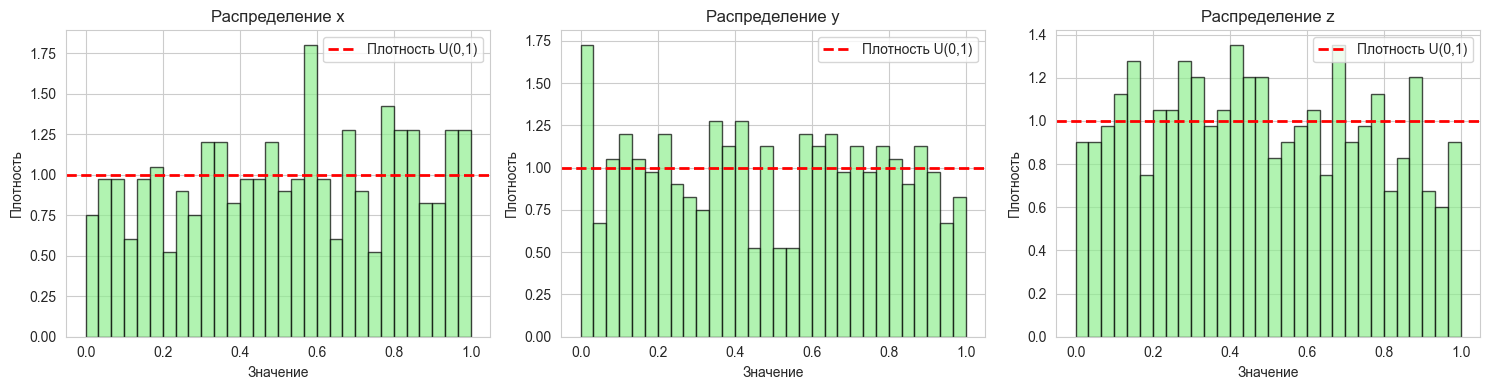

In [5]:
# Визуализация распределений
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, v) in zip(axes, [("x", x), ("y", y), ("z", z)]):
    ax.hist(v, bins=30, density=True, alpha=0.7, edgecolor="k", color="lightgreen")
    ax.axhline(1.0, color="red", ls="--", linewidth=2, label="Плотность U(0,1)")
    ax.set_title(f"Распределение {name}")
    ax.set_xlabel("Значение")
    ax.set_ylabel("Плотность")
    ax.legend()
plt.tight_layout()
plt.savefig("output/randu_hist.png", dpi=120)
plt.show()


Все три гистограммы (x, y, z) «пляшут» вокруг красной линии. Где-то столбик выше (1.75), где-то ниже (0.5). Это называется выборочный шум (или случайные колебания). Но общей тенденции (например, чтобы слева было всегда пусто, а справа густо) нет.
Вывод: Все три столбца (x, y, z) визуально распределены равномерно. График подтверждает результаты теста Колмогорова-Смирнова (p > 0.05, H0 не отверглась).

2. (в чем подвох RANDU)

Дефект генератора RANDU не в том, что числа не равномерны по отдельности (как видно на графике — они идеальны). Дефект в том, как они связаны друг с другом (в 3D они лежат на плоскостях).
Эти гистограммы показывают, что одномерные распределения x, y и z идеально равномерны, что подтверждает тест KS. Однако, как известно из истории RANDU, если построить эти точки в трехмерном пространстве, они лягут на плоскости. Это доказывает, что одномерные тесты (и гистограммы) не видят скрытых зависимостей между переменными